# Phân tích dữ liệu trước huấn luyện

Trong buổi luyện ba việc ở bài trước, bài văn bản của một học sinh đạt validation gần như hoàn hảo chỉ sau vài phút. Nhưng khi thử model trên vài tài liệu lấy từ nguồn khác, dự đoán lại thất thường. Có nên dùng thời gian còn lại để tăng số epoch? Trước khi làm vậy, cần hỏi: **validation đang chứa ví dụ mới, hay chỉ chứa bản khác của những tài liệu model đã thấy?** Một điểm rất cao có thể đang đo khả năng nhớ nguồn dữ liệu, không phải năng lực mà bài toán cần.

Phân tích khám phá dữ liệu (exploratory data analysis, EDA) là quá trình đặt câu hỏi, tính thống kê, nhìn mẫu và kiểm giả thuyết về dữ liệu. EDA không kết thúc ở một bảng `describe()`. Một phát hiện phải dẫn tới quyết định: sửa cách đọc file, giữ các mẫu cùng nguồn trong một nhóm, bỏ một đặc trưng không có ở lúc dự đoán, hoặc kiểm tra thêm một miền dữ liệu.

> **Mục tiêu sau bài này**
>
> - Đọc schema, xác định đơn vị mẫu và kiểm ID, dữ liệu thiếu, mẫu trùng, nhãn mâu thuẫn.
> - Chọn validation theo người, tài liệu, camera hoặc thời gian khi mục tiêu yêu cầu.
> - Phân biệt trùng lặp, nhãn nhiễu, đường tắt, rò rỉ và các kiểu lệch phân phối.
> - Dùng baseline, ablation và lát dữ liệu kèm số mẫu để kiểm một đặc trưng đang giúp model tổng quát hay chỉ giúp nhớ nguồn.

## Đọc file trước khi đọc model

Ta bắt đầu bằng một bảng nhỏ tự tạo. `id` định danh một dòng, `document` định danh tài liệu gốc; hai khóa không có cùng ý nghĩa. Các đoạn cắt từ cùng tài liệu có thể mang dấu vết chung. `device` là thiết bị thu dữ liệu, `signal` là một đặc trưng số và `label` là nhãn nhị phân.

In [ ]:
from io import StringIO
import numpy as np
import pandas as pd

csv_data = """id,document,device,signal,label
001,doc-a,old,1.2,1
002,doc-a,old,1.3,1
003,doc-b,old,-0.8,0
004,doc-c,new,,1
005,doc-d,new,0.4,0
006,doc-e,old,-0.8,0
007,doc-b,old,-0.8,1
003,doc-b,old,-0.8,0
"""
df = pd.read_csv(StringIO(csv_data), dtype={"id": str})
print("shape", df.shape)
print("missing", df.isna().sum().to_dict())
print("duplicated ids", df.loc[df["id"].duplicated(), "id"].tolist())
print("labels", df["label"].value_counts().sort_index().to_dict())

shape (8, 5)
missing {'id': 0, 'document': 0, 'device': 0, 'signal': 1, 'label': 0}
duplicated ids ['003']
labels {0: 4, 1: 4}


Bảng có tám dòng nhưng không có tám ID khác nhau: `003` lặp lại, và một giá trị `signal` bị thiếu. Ta chưa điền thiếu ngay. Trước hết cần biết đó là lỗi đọc file, lỗi cảm biến, hay thông tin “không đo được” có ý nghĩa; đếm thiếu theo từng nguồn thường nói nhiều hơn đếm tổng. Nếu số bị viết bằng dấu phẩy thập phân, đọc sai separator có thể biến cả cột thành chuỗi. Kiểm dtype và vài dòng thật giúp phát hiện lỗi này sớm hơn việc sửa model.

Trong một thư mục ảnh hoặc âm thanh, schema không nằm gọn trong CSV. Nó còn gồm đường dẫn, phần mở rộng, kích thước ảnh, số kênh, sample rate và ánh xạ nhãn. Ta kiểm một số file từ từng nhóm, đặc biệt file nhỏ nhất, lớn nhất và file bị thiếu. Nếu ảnh màu có ba kênh nhưng processor nhận grayscale, hoặc audio bị hiểu sai sample rate, đầu vào đã đổi ý nghĩa trước khi model nhìn thấy nó.

**Hỏi nhanh.** Hai dòng có `id` khác nhau nhưng cùng `document`. Điều này nói gì về cách chia validation?

- A. Hai dòng có thể chung nguồn, và cách chia tùy vào mục tiêu
- B. Hai dòng độc lập vì mỗi dòng có ID riêng, nên chia theo dòng
- C. Hai dòng là bản trùng, nên phải xóa bớt một dòng
- D. Hai dòng mang hai nhãn khác nhau, vì ID khác nhau

<details><summary>Đáp án</summary>

A. Hai dòng có thể chung nguồn, và cách chia tùy vào mục tiêu

ID chỉ định danh dòng, không nói gì về nguồn. Hai đoạn cùng tài liệu chưa phải bản trùng nên không cần xóa, và nhãn của chúng có thể giống hoặc khác. Nếu mục tiêu là đoán tài liệu mới, hai dòng phải nằm cùng một phía. Nếu mục tiêu là đoán đoạn mới trong tài liệu đã biết, chia theo dòng lại đúng câu hỏi.

</details>

**Hỏi nhanh.** Trên dữ liệu đầy đủ, đếm ô thiếu theo thiết bị thì thấy `signal` thiếu 0% ở `old` nhưng thiếu 60% ở `new`. Bước tiếp theo nên là gì?

- A. Xem file gốc của thiết bị mới trước khi điền
- B. Điền mean của cả cột, vì thiếu là ngẫu nhiên
- C. Bỏ cột `signal`, vì cột này thiếu quá nhiều
- D. Bỏ mọi dòng `new`, vì thiết bị này ghi lỗi

<details><summary>Đáp án</summary>

A. Xem file gốc của thiết bị mới trước khi điền

Ô thiếu dồn vào một nguồn, nên không còn là thiếu ngẫu nhiên. Thiết bị mới có thể ghi cột khác tên, ghi đơn vị khác, hoặc thật sự không đo đại lượng này. Điền mean chung biến 60% dòng `new` thành cùng một giá trị, và model nhận ra thiết bị qua chính giá trị điền ấy. Bỏ cột làm mất tín hiệu ở `old`. Bỏ dòng `new` làm mất đúng miền có thể xuất hiện trong test. Biết nguyên nhân rồi mới chọn cách xử lý: sửa cách đọc, điền kèm một cột chỉ báo thiếu, hay xử lý riêng theo nguồn.

</details>

## Mẫu trùng không chỉ là hai hàng giống hệt

`df.duplicated()` tìm hàng trùng toàn bộ. Nhưng nếu hai bản ảnh khác tên file, hai đoạn văn khác dấu cách, hoặc một audio bị đổi định dạng, phép so toàn bộ hàng không thấy chúng. Ta cần chọn “nội dung nào quyết định đây là cùng một mẫu”. Với dữ liệu thật, có thể chuẩn hóa khoảng trắng rồi băm văn bản, băm bytes ảnh để tìm trùng chính xác, hoặc so embedding để đề xuất cặp gần trùng. Cặp gần trùng cần được xem lại; embedding gần nhau không chứng minh chúng là cùng dữ liệu.

**Hỏi nhanh.** Hai bài đánh giá chỉ khác nhau ở chữ hoa đầu câu và một dấu cách thừa. Băm bytes gốc thì ra hai mã hash khác nhau. Ta kết luận được gì?

- A. Hai bài chắc chắn khác nội dung, vì hash khác nhau
- B. Hàm băm bị lỗi, cần đổi sang một thuật toán băm khác
- C. Phải so embedding mới biết hai bài có trùng không
- D. Hash chỉ so bytes, nên cần chuẩn hóa văn bản rồi băm lại

<details><summary>Đáp án</summary>

D. Hash chỉ so bytes, nên cần chuẩn hóa văn bản rồi băm lại

Hash khác nhau chỉ nói bytes khác nhau, kể cả khi chỉ khác đúng một dấu cách. Đổi thuật toán băm không thay đổi được điều đó. Hạ chữ thường và gộp khoảng trắng rồi băm lại sẽ bắt được loại trùng này, vừa rẻ vừa chính xác. Embedding dành cho những cặp diễn đạt khác hẳn nhau, và vẫn cần người xem lại. Chuẩn hóa tới mức nào là tùy bài. Nếu chữ hoa mang thông tin về nhãn thì đừng hạ chữ thường.

</details>



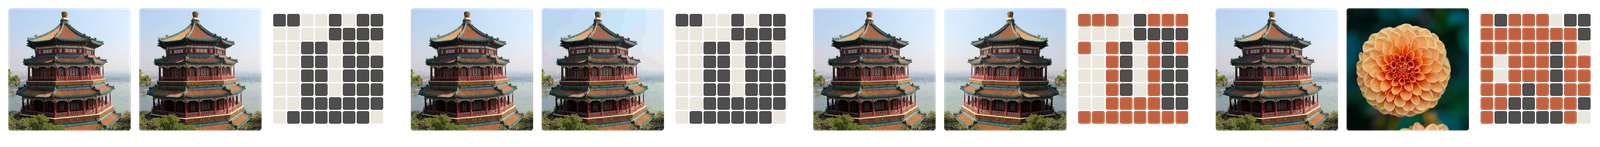

Ở bảng nhỏ, ta nhóm theo nguồn, thiết bị và tín hiệu để kiểm nhãn mâu thuẫn. Cùng bộ đặc trưng xuất hiện với cả 0 và 1 là một *ứng viên cần kiểm*, chưa đủ kết luận nhãn sai: có thể ta thiếu một đặc trưng quan trọng hoặc label được định nghĩa theo từng đoạn khác nhau.

In [ ]:
key = ["document", "device", "signal"]
unique_labels = df.groupby(key, dropna=False)["label"].nunique()
conflicts = unique_labels[unique_labels > 1]
print("conflicting feature groups", len(conflicts))
print(conflicts.index.tolist())
print("exact duplicated rows", int(df.duplicated().sum()))

conflicting feature groups 1
[('doc-b', 'old', -0.8)]
exact duplicated rows 1


Nhóm `doc-b` có hai nhãn, còn một hàng trùng hoàn toàn. Ta xem lại nguồn của hai nhãn trước khi sửa. Không được lấy dự đoán model làm nhãn “đúng” rồi tự động xóa mọi mẫu model đoán sai. Nếu model học một đường tắt, chính những mẫu trái đường tắt có thể là phần dữ liệu giá trị nhất.



Nhãn nhiễu và ngoại lai cũng khác nhau. Một căn hộ rất đắt có thể là thật; một nhãn ảnh sai là lỗi ghi nhãn. Dùng quy tắc “mọi điểm xa trung bình đều xóa” sẽ làm model không học được các trường hợp hiếm. Quyết định sửa hay xóa cần căn cứ định nghĩa nhãn, nguồn và điều kiện bài thi cho phép. Bản trùng còn gây hại ở model sinh: một ảnh lặp lại nhiều lần trong dữ liệu học dễ bị nhớ và sinh lại gần như y hệt.

**Hỏi nhanh.** Hai mẫu có đặc trưng giống hệt nhau, nhưng nhãn lại khác nhau. Việc đầu tiên nên làm là gì?

- A. Sửa cả hai nhãn theo dự đoán của model
- B. Xem nguồn và cách gán nhãn của hai mẫu
- C. Xóa mẫu mang nhãn ít gặp hơn
- D. Bỏ cả hai mẫu khỏi train và validation

<details><summary>Đáp án</summary>

B. Xem nguồn và cách gán nhãn của hai mẫu

Thống kê chỉ báo có mâu thuẫn, chưa nói nguyên nhân. Có thể một nhãn sai, có thể bảng thiếu một đặc trưng phân biệt hai mẫu, cũng có thể nhãn được định nghĩa khác nhau giữa hai đợt gán. Dự đoán của model không phải nhãn chuẩn. Xóa nhãn ít gặp, hay xóa cả hai khi chưa biết nguyên nhân, có thể bỏ đi đúng những mẫu khó mà test cũng chứa.

</details>

## Validation phải giống câu hỏi lúc sử dụng

Giả sử có 60 tài liệu, mỗi tài liệu được cắt thành bốn đoạn. Một dấu vết như watermark hoặc cách ghi âm gần như không đổi giữa bốn đoạn. Nếu chia ngẫu nhiên từng đoạn, phần train và validation thường cùng chứa một tài liệu. Model chỉ cần nhận ra dấu vết để nhớ nhãn tài liệu.

Ta tạo thí nghiệm cực nhỏ để nhìn cơ chế này. Mỗi tài liệu có một vector one-hot riêng, đóng vai dấu vết nguồn. Nhãn được sinh ngẫu nhiên theo tài liệu, nên vector đó **không mang quy luật nào sang tài liệu mới**: model chỉ có thể làm tốt bằng cách nhớ.

In [ ]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

rng = np.random.default_rng(82)
groups = np.repeat(np.arange(60), 4)
document_labels = rng.integers(0, 2, size=60)
X = np.eye(60)[groups]             # (240, 60), dấu vết nguồn
y = document_labels[groups]       # (240,), nhãn theo tài liệu
rows = np.arange(len(y))
random_train, random_val = train_test_split(
    rows, test_size=0.25, random_state=0, stratify=y)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=1)
group_train, group_val = next(splitter.split(X, y, groups))

for name, train_rows, val_rows in [
    ("random", random_train, random_val),
    ("group", group_train, group_val),
]:
    model = KNeighborsClassifier(n_neighbors=1).fit(X[train_rows], y[train_rows])
    prediction = model.predict(X[val_rows])
    overlap = set(groups[train_rows]) & set(groups[val_rows])
    print(name, "overlap", len(overlap),
          "accuracy", f"{accuracy_score(y[val_rows], prediction):.3f}")
    if name == "group":
        print("group predictions", np.unique(prediction).tolist(),
              "val label counts", np.bincount(y[val_rows]).tolist())

random overlap 39 accuracy 1.000
group overlap 0 accuracy 0.733
group predictions [1] val label counts [16, 44]


Đọc `overlap` trước accuracy. Chia ngẫu nhiên để 39 tài liệu nằm ở cả hai phía, nên 1-NN chỉ cần nhận ra dấu vết one-hot để trả lại nhãn của đoạn cùng tài liệu: accuracy 1.000. Chia theo nhóm giữ `overlap 0`, mọi tài liệu validation đều mới. Vector one-hot của một tài liệu mới cách đều mọi hàng train, nên 1-NN gặp hòa khoảng cách và trả nhãn của hàng train đứng đầu, ở đây là nhãn 1. Dòng thứ ba xác nhận: mọi dự đoán đều là 1, và validation có 44 nhãn 1 trên 60 dòng, nên accuracy là $44/60\approx0.733$. Con số này chỉ là tỉ lệ lớp, không phải bằng chứng model hiểu tài liệu mới. Ta giữ seed cố định để đọc hiện tượng, không đổi seed nhằm tìm split cao điểm hơn.



**Hỏi nhanh.** Ở group-split, train có 100 nhãn 1 và 80 nhãn 0. Baseline luôn đoán lớp đông nhất của train đạt accuracy bao nhiêu trên cùng validation?

- A. 0.500
- B. 0.267
- C. 0.556
- D. 0.733

<details><summary>Đáp án</summary>

D. 0.733

Lớp đông nhất của train là 1. Validation có 44 nhãn 1 trên 60 dòng, nên baseline đạt $44/60 \approx 0.733$, đúng bằng 1-NN, tức model không hơn baseline chút nào. 0.267 là đoán lớp 0. 0.556 là tỉ lệ nhãn 1 của train, $100/180$, không phải của validation. 0.500 là mức đoán ngẫu nhiên đều. Hãy đặt baseline lớp đông nhất cạnh mọi con số accuracy, nhất là khi các lớp lệch nhau.

</details>

Tính tay giải thích vì sao chia ngẫu nhiên gần như luôn tạo nguồn chung. Với một tài liệu có bốn đoạn và mỗi đoạn độc lập được đưa vào validation với xác suất $0.25$, xác suất tài liệu xuất hiện ở cả hai phía là

$$1-(0.75)^4-(0.25)^4\approx0.680.$$

Mô hình Bernoulli này dự đoán khoảng $60\cdot0.680\approx40.8$ tài liệu bị chia đôi; thí nghiệm có 39. Xác suất một tài liệu nằm trọn ở validation chỉ là $0.25^4\approx0.004$, và quả thật cả 39 tài liệu có mặt ở validation đều có đoạn ở train. `train_test_split` cố định số dòng nên không theo đúng giả định độc lập, nhưng hai con số vẫn khớp về độ lớn. Khi mục tiêu là ảnh từ camera mới, chia theo camera; khi dự đoán tương lai, giữ khoảng thời gian sau làm validation. `GroupShuffleSplit(test_size=0.25)` chọn 25% số nhóm, không bảo đảm 25% số dòng khi các nhóm lớn nhỏ khác nhau.

**Hỏi nhanh.** Có 40 tài liệu. 4 tài liệu dài, mỗi tài liệu 100 đoạn. 36 tài liệu ngắn, mỗi tài liệu 5 đoạn. `GroupShuffleSplit(test_size=0.25)` chọn 10 tài liệu làm validation. Số dòng của validation có thể nằm trong khoảng nào?

- A. Luôn đúng 145 dòng
- B. Từ 50 đến 430 dòng
- C. Từ 10 đến 40 dòng
- D. Từ 50 đến 400 dòng

<details><summary>Đáp án</summary>

B. Từ 50 đến 430 dòng

Tổng cộng có 580 dòng, 25% là 145, nhưng splitter đếm tài liệu chứ không đếm dòng. Ít nhất là 10 tài liệu ngắn, $10\cdot 5 = 50$ dòng, tức 8.6%. Nhiều nhất là 4 tài liệu dài và 6 tài liệu ngắn, $400 + 30 = 430$ dòng, tức 74%. “10 đến 40” là nhầm số tài liệu với số dòng. 400 là quên 6 tài liệu ngắn đi kèm. Khi các nhóm chênh nhau về kích thước, hãy in số dòng và tỉ lệ lớp của từng phía sau khi chia.

</details>



## Đường tắt và rò rỉ

Một đường tắt (shortcut) là tín hiệu dễ học, tương quan với nhãn trong dữ liệu đang có, nhưng không phải cơ chế ta muốn model nắm. Ví dụ ảnh lớp 1 phần lớn chụp bằng một camera có viền đỏ, và model học viền. Viền có mặt lúc dự đoán nên đây không phải rò rỉ; nó chỉ gây hại khi dữ liệu mới không còn giữ quan hệ giữa viền và nhãn. Rò rỉ (leakage) là dùng thông tin không có ở lúc dự đoán, như kết quả kiểm định ghi sau khi nhãn đã được xác định: nó làm validation đẹp giả ngay cả khi test cùng nguồn. Sửa rò rỉ là bỏ thông tin ấy; với đường tắt, phải kiểm test có giữ quan hệ ấy không rồi mới quyết định.

Một phép thử nhanh cho đường tắt là model chỉ dùng thông tin nằm ngoài nội dung: kích thước file, độ phân giải, định dạng, thứ tự dòng, tên thư mục. Nếu model ấy vượt xa baseline lớp đông nhất, nhãn đang lộ qua cách dữ liệu được thu thập, và một model mạnh hơn cũng có thể đi đúng đường đó.

**Hỏi nhanh.** Trong train, phần lớn bài đánh giá tiêu cực kết thúc bằng dòng “Gửi từ ứng dụng X”, còn bài tích cực hiếm khi có. Dòng chữ này có sẵn lúc dự đoán. Đây là loại vấn đề gì, và khi nào nó gây hại?

- A. Là rò rỉ, gây hại ngay cả khi test cùng nguồn
- B. Là rò rỉ, chỉ gây hại khi test lấy từ nguồn khác
- C. Là đường tắt, vô hại vì có sẵn lúc dự đoán
- D. Là đường tắt, gây hại khi test làm đổi quan hệ ấy

<details><summary>Đáp án</summary>

D. Là đường tắt, gây hại khi test làm đổi quan hệ ấy

Thông tin có mặt lúc dự đoán nên không phải rò rỉ. Nó là một đường tắt: tương quan với nhãn là do cách thu thập, chứ không do nội dung khen hay chê. Nếu test lấy cùng hỗn hợp nguồn, model dùng nó vẫn đạt điểm. Nếu test đến từ ứng dụng khác, hoặc tỉ lệ các ứng dụng đổi đi, điểm sẽ rơi. “Có sẵn lúc dự đoán” chỉ loại trừ rò rỉ, không bảo đảm quan hệ còn đúng ở miền mới.

</details>

## Lệch phân phối và ablation

Lệch phân phối (distribution shift) xảy ra khi train và nơi đánh giá không theo cùng một phân phối. Có ba kiểu thường gặp. Phân phối đặc trưng đổi (covariate shift): ảnh từ camera mới tối hơn, nhưng một ảnh vẫn mang nhãn như trước. Tỉ lệ lớp đổi (label shift): test có nhiều ca dương hơn, còn hình dạng mỗi lớp giữ nguyên; xác suất model trả ra vẫn nghiêng về tỉ lệ cũ, nên ngưỡng chọn trên validation cũ cần được chọn lại. Quan hệ đặc trưng–nhãn đổi (concept shift): cùng đầu vào nhưng nhãn đúng đã khác, như khi đường tắt bị đảo. Hai histogram khác nhau chỉ cho thấy đặc trưng đã đổi; không có nhãn thì chưa kết luận được quan hệ với nhãn có đổi hay không. Bộ benchmark [WILDS](https://proceedings.mlr.press/v139/koh21a.html) gom các bộ dữ liệu mà phần đánh giá đến từ bệnh viện, vùng hoặc thời điểm khác train, để đo khoảng cách giữa đánh giá trong miền và ngoài miền (out-of-distribution, OOD). Khi model đã chạy thật mà nhãn đến muộn, như phải 3 tháng mới biết khách có trả nợ, hãy theo dõi những thứ có ngay: phân phối đầu vào, tỉ lệ dự đoán dương, phân phối score; một thay đổi lớn ở đó là tín hiệu phải kiểm.

**Hỏi nhanh.** Histogram của một đặc trưng trên test không nhãn lệch hẳn so với train. Ta kết luận được gì?

- A. Nhãn test có nhiều lỗi ghi nhãn, do đến từ nguồn khác
- B. Đặc trưng đã đổi, nhưng tác động lên nhãn thì chưa biết
- C. Quan hệ giữa đặc trưng và nhãn đã bị đảo ngược
- D. Model chắc chắn sẽ đạt điểm kém trên test

<details><summary>Đáp án</summary>

B. Đặc trưng đã đổi, nhưng tác động lên nhãn thì chưa biết

Histogram chỉ mô tả đặc trưng. Nó không nói gì về nhãn test, không chứng minh quan hệ với nhãn đã đổi, và chưa chắc làm model kém đi. Nếu model dựa vào một cơ chế vẫn đúng ở vùng giá trị mới, điểm có thể giữ được. Bước tiếp theo là xem lát validation gần vùng giá trị mới nhất, hoặc dùng những phép kiểm khác mà đề cho phép.

</details>

Khi đề cho input test không nhãn và cho phép phân tích chúng, có thể kiểm nhiều cột cùng lúc: gán 0 cho hàng train, 1 cho hàng test, rồi huấn luyện một classifier phân biệt hai nguồn (adversarial validation). AUC gần 0.5 nghĩa là classifier không tách được hai tập bằng các cột đã đưa vào; AUC gần 1 nghĩa là có cột lệch mạnh, và độ quan trọng của từng cột chỉ ra chỗ cần xem. Phép kiểm này chỉ so đầu vào: nếu đầu vào giữ nguyên mà quan hệ với nhãn đổi, nó không thấy.

**Hỏi nhanh.** Một classifier phân biệt train với test đạt AUC 0.98, và cột quan trọng nhất là `id`, vốn tăng dần theo thời điểm thu dữ liệu. Nên làm gì tiếp?

- A. Dùng classifier này làm model chính, vì AUC rất cao
- B. Bỏ qua kết quả, vì `id` chỉ là số thứ tự vô nghĩa
- C. Test đến sau train, nên chia validation theo `id`
- D. Yên tâm, vì AUC cao báo trước điểm cao cho model chính

<details><summary>Đáp án</summary>

C. Test đến sau train, nên chia validation theo `id`

AUC 0.98 là nhờ `id`, cho biết test nằm sau train theo thời gian. Validation nên mô phỏng điều đó: giữ đoạn `id` cuối của train làm validation thay cho chia ngẫu nhiên, và không đưa `id` vào feature, vì `id` của test nằm ngoài vùng mà train đã thấy. Classifier này đoán một hàng thuộc train hay test, chứ không đoán nhãn của bài toán, nên AUC của nó không nói gì về điểm của model chính.

</details>

Thí nghiệm sau tạo một concept shift có kiểm soát. `signal` liên hệ với nhãn theo cùng một cơ chế ở cả hai miền. `shortcut` trùng nhãn ở khoảng 95% mẫu của miền nguồn nhưng chỉ 5% ở miền mới, tức quan hệ bị đảo. Ta biết điều này vì chính ta sinh dữ liệu; với dữ liệu thi, đó là một giả thuyết cần kiểm bằng nguồn và validation được phép.



In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

def make_domain(n, shortcut_agreement, seed):
    generator = np.random.default_rng(seed)
    signal = generator.normal(size=n)
    labels = (signal + generator.normal(0, 0.5, n) > 0).astype(int)
    shortcut = 2 * labels - 1
    flips = generator.random(n) > shortcut_agreement
    shortcut[flips] *= -1
    features = np.column_stack([signal, shortcut])
    return features, labels

X_source, y_source = make_domain(800, 0.95, 1)
X_shift, y_shift = make_domain(400, 0.05, 2)
train_rows, val_rows = train_test_split(
    np.arange(800), test_size=0.25, random_state=3, stratify=y_source)

for name, columns in [("both", [0, 1]), ("signal-only", [0])]:
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
    model.fit(X_source[train_rows][:, columns], y_source[train_rows])
    in_domain = model.predict(X_source[val_rows][:, columns])
    out_domain = model.predict(X_shift[:, columns])
    print(name,
          "in-domain", f"{accuracy_score(y_source[val_rows], in_domain):.3f}",
          "shifted", f"{accuracy_score(y_shift, out_domain):.3f}")

both in-domain 0.970 shifted 0.383
signal-only in-domain 0.830 shifted 0.863


Model dùng cả hai cột đạt 0.970 trong miền nguồn nhưng rơi xuống 0.383 khi đường tắt đảo, dưới cả mức đoán ngẫu nhiên. Model chỉ dùng `signal` mất điểm trong miền nguồn (0.830) nhưng giữ 0.863 ở miền mới. Đây là ablation: bỏ một thành phần rồi đo lại trong điều kiện kiểm soát. Nó chỉ ra vai trò của cột, không chứng minh mọi đặc trưng gắn với nguồn đều phải bỏ: nếu test thật sự cùng nguồn và quan hệ giữ nguyên, bỏ cột lại làm mất điểm. Một ablation cũng chỉ đáng tin khi chênh lệch lớn hơn dao động giữa các fold hoặc seed. Ở đây chênh 0.14 trong miền nguồn (200 mẫu validation) và 0.48 ở miền mới (400 mẫu) đều lớn; chạy lại với 20 cặp seed khác, chiều chênh lệch không đổi (chênh in-domain nhỏ nhất 0.06, chênh ở miền mới nhỏ nhất 0.34). Chênh vài phần nghìn thì chưa nói được gì.



**Hỏi nhanh.** Đề nói rõ test lấy từ cùng nguồn, cùng giai đoạn với train, nên quan hệ của `shortcut` giữ nguyên. Theo output ở trên, nên chọn cấu hình nào?

- A. Dùng cả hai cột, vì số in-domain mới là ước lượng đúng cho test
- B. Chỉ dùng `signal`, vì đường tắt nào cũng là rủi ro
- C. Chỉ dùng `signal`, vì điểm shifted của nó cao hơn
- D. Chọn cấu hình có trung bình in-domain và shifted cao hơn

<details><summary>Đáp án</summary>

A. Dùng cả hai cột, vì số in-domain mới là ước lượng đúng cho test

Khi test cùng phân phối với train, accuracy in-domain, 0.970 so với 0.830, mới ước lượng đúng điểm test. Cột shifted trả lời một câu hỏi không có trong đề. Quyết định sẽ đảo lại khi đề báo test đến từ miền mới, hoặc khi lát validation theo nguồn cho thấy quan hệ đã đổi. Trung bình hai số là trộn hai kịch bản mà chỉ một cái xảy ra. Theo cách ấy, `signal` sẽ thắng, khoảng 0.85 so với 0.68, vì một lý do không liên quan đến đề.

</details>

## Nhìn từng lát dữ liệu để biết model sai ở đâu

Accuracy trung bình có thể che một nhóm khó. Có 90 mẫu từ camera cũ, model đúng 81; có 10 mẫu camera mới, model đúng 2. Accuracy chung là $83/100=0.83$, nhưng camera mới chỉ $2/10=0.20$. Nếu tương lai đa số ảnh đến từ camera mới, số 0.83 không dự báo tốt mục tiêu đó. Một nhóm có ít mẫu cũng cho ước lượng rất nhiễu; ghi số lượng cạnh metric để không nhầm hai lỗi trên ba mẫu với hai trăm lỗi trên ba trăm mẫu. Gộp lát cũng có thể đảo kết luận. Phương pháp A chữa khỏi tỉ lệ cao hơn B ở cả sỏi thận nhỏ (81/87 so với 234/270) lẫn sỏi lớn (192/263 so với 55/80), nhưng gộp lại A chỉ 273/350, thua B 289/350, vì A được dùng nhiều cho ca khó. Đó là nghịch lý Simpson.

In [ ]:
slice_counts = pd.DataFrame({
    "device": ["old", "new"],
    "n": [90, 10],
    "correct": [81, 2],
})
slice_counts["accuracy"] = slice_counts["correct"] / slice_counts["n"]
print(slice_counts.to_string(index=False))
print("overall", slice_counts["correct"].sum() / slice_counts["n"].sum())
print("equal-domain mean", slice_counts["accuracy"].mean())

device  n  correct  accuracy
   old 90       81       0.9
   new 10        2       0.2
overall 0.83
equal-domain mean 0.55




Mean ngang hai miền là $0.55$, khác accuracy chung $0.83$ vì hai phép đo có trọng số khác. Ta không tự thay metric của đề bằng mean ngang miền; ta dùng nó làm chẩn đoán. Metric chính vẫn theo statement, kèm lát dữ liệu giúp hiểu lý do thắng thua.

Số mẫu quyết định độ tin của từng con số. Với $n$ mẫu độc lập và accuracy $p$, sai số chuẩn của accuracy xấp xỉ $\sqrt{p(1-p)/n}$, và khoảng $p\pm2$ sai số chuẩn cho một vùng hợp lý của accuracy thật. Lát nhỏ cho khoảng rộng: một lát vài chục mẫu đủ để báo động, nhưng chưa đủ để xếp hạng hai model có điểm gần nhau.

**Hỏi nhanh.** Theo công thức sai số chuẩn, accuracy của camera mới, $2/10$, và của camera cũ, $81/90$, có sai số chuẩn xấp xỉ bao nhiêu?

- A. Camera mới 0.016, camera cũ 0.001
- B. Camera mới 0.03, camera cũ 0.13
- C. Camera mới 0.13, camera cũ 0.03
- D. Camera mới 0.40, camera cũ 0.30

<details><summary>Đáp án</summary>

C. Camera mới 0.13, camera cũ 0.03

Camera mới có $\sqrt{0.2\cdot 0.8/10} = \sqrt{0.016} \approx 0.13$. Camera cũ có $\sqrt{0.9\cdot 0.1/90} = \sqrt{0.001} \approx 0.03$. Khoảng $0.20 \pm 0.25$ của camera mới trải từ gần 0 tới khoảng 0.45: chắc chắn là yếu, nhưng chưa biết yếu tới đâu. 0.016 và 0.001 là quên lấy căn. 0.40 và 0.30 là quên chia cho $n$. Đảo hai số là tưởng nhóm lớn hơn thì nhiễu hơn.

</details>



## Bẫy và quyết định trong buổi luyện

Không fit scaler, imputer, vocabulary hoặc feature selection trên toàn bộ dữ liệu rồi mới chia. Chia trước, fit trên train, transform phần còn lại. `Pipeline` giúp giữ thứ tự ấy trong cross-validation; nó không tự biết group nào cần nằm cùng một phía. [scikit-learn — Common pitfalls](https://scikit-learn.org/1.7/common_pitfalls.html).

Không dùng nhãn test kín để xem “nhóm nào khó”. Nếu statement cho dữ liệu không nhãn, ta có thể kiểm schema hoặc phạm vi giá trị trong giới hạn cho phép, nhưng việc học từ test không nhãn, transductive inference hay tìm trùng train–test có được dùng hay không phải theo đúng quy định. EDA không cấp thêm quyền tiếp cận dữ liệu.

Lọc nhãn nhiễu cũng có ranh giới riêng. Nếu bỏ những mẫu mà model đoán sai với độ tự tin cao, chỉ bỏ trong train của từng fold; validation giữ nguyên, để cấu hình trước và sau khi lọc được chấm trên cùng một tập. Bộ chấm của đề không lọc test theo ý ta.

**Hỏi nhanh.** Một đội bỏ 10% số mẫu mà model 5-fold đoán sai với độ tự tin cao, rồi chạy lại 5-fold trên phần còn lại. Điểm CV từ 0.81 lên 0.90. Đọc kết quả này thế nào?

- A. Chưa so được, vì validation mới đã bỏ đi những mẫu khó
- B. Nhãn nhiễu đã được dọn, nên test sẽ tăng khoảng 0.09
- C. Nên lặp thêm vài vòng lọc cho tới khi CV gần 1.0
- D. Kết quả sai, vì không được chạy 5-fold sau khi lọc

<details><summary>Đáp án</summary>

A. Chưa so được, vì validation mới đã bỏ đi những mẫu khó

Hai con số được chấm trên hai tập khác nhau. Lần sau đã bỏ đúng những mẫu model sai, nên điểm tăng gần như chắc chắn, dù nhãn có nhiễu hay không. Test thì vẫn chứa những mẫu khó ấy. Phép so công bằng là lọc trong phần train của từng fold, và chấm trên validation gốc. Lặp lọc đưa CV dần tới 1.0 bằng cách bỏ dần mọi mẫu khó. Chạy 5-fold sau khi lọc không sai về kỹ thuật. Cái sai là chấm trên một tập đã bị đổi.

</details>

Quay lại bài văn bản ở đầu buổi, việc đáng chạy tiếp là kiểm document overlap và đánh giá trên tài liệu mới. Nếu điểm giảm sau khi sửa split, đó là phép đo đã trung thực hơn. Ta giữ split đã sửa để chọn model, lưu một vài cặp mẫu cho thấy cơ chế, và ghi rõ phát hiện nào là chắc chắn, phát hiện nào còn là giả thuyết. Không tiếp tục dùng con số cũ như thành tích của bản mới.

## Khi đi thi

- **Kiểm hợp đồng dữ liệu trước model.** Đọc vài dòng thật, dtype, số dòng mỗi file, ID trùng và ô thiếu theo từng nguồn; một lỗi đọc file làm hỏng mọi thí nghiệm phía sau.
- **Tìm khóa nhóm trước khi chia.** Người, tài liệu, camera, phiên hay thời gian: chọn khóa theo “mẫu mới” của đề, rồi in số nhóm chung giữa hai phía và số dòng mỗi phía.
- **Đặt hai baseline rẻ cạnh model.** Baseline lớp đông nhất cho biết model có học gì không; model chỉ dùng metadata mà điểm cao là dấu hiệu đường tắt.
- **So test với train trong phạm vi đề cho phép.** Histogram từng cột, phân phối dự đoán, adversarial validation; nếu đề không cho dùng input test, chỉ dựa vào thông tin statement công bố.
- **Ghi kết quả kèm split, số mẫu và dao động.** Chênh lệch nhỏ hơn dao động giữa fold không đủ để chọn; lưu split đã sửa để mọi cấu hình được chấm trên cùng một tập.

## Tóm tắt

EDA biến dữ liệu thành câu hỏi có thể kiểm. Schema cho biết mỗi cột và mỗi mẫu có nghĩa gì; kiểm trùng và nhãn mâu thuẫn tìm ứng viên cần xem nguồn; validation theo nhóm hoặc thời gian đo đúng mục tiêu. Đường tắt có mặt lúc dự đoán nhưng chỉ đúng trong miền cũ, còn rò rỉ là thông tin không có lúc dự đoán. Lệch phân phối có thể ở đặc trưng, ở tỉ lệ lớp hoặc ở quan hệ với nhãn; histogram hay adversarial validation chỉ thấy phần đầu vào. Baseline, ablation và lát dữ liệu kèm số mẫu giúp phân biệt model dùng tín hiệu bền vững hay đường tắt. Điểm thấp hơn sau khi sửa split có thể là một tiến bộ trong đánh giá.

## Kiểm tra cuối bài

**Câu 1.** Một đội ghép điểm đánh giá phim từ ba trang web để làm hệ gợi ý. Trang A chấm từ 1 đến 5, trang B từ 1 đến 10, trang C từ 1 đến 100. Người dùng và phim đã được khớp giữa ba trang. Trước khi học trên bảng điểm gộp, cần làm bước nào?

- A. Đưa điểm của từng trang về cùng một thang, chẳng hạn $[0, 1]$
- B. Gộp nguyên điểm, vì model sẽ tự học được khác biệt thang đo
- C. Bỏ trang C, vì điểm của nó lớn và lấn át hai trang kia
- D. Chuẩn hóa z-score một lần trên cả cột điểm đã gộp

<details><summary>Đáp án</summary>

A. Đưa điểm của từng trang về cùng một thang, chẳng hạn $[0, 1]$

Cùng là “rất thích”, trang A ghi 5 còn trang C ghi 100. Gộp nguyên thì một con số mang nghĩa khác nhau tùy nguồn. Min–max theo từng trang, tức $(r - 1)/4$, $(r - 1)/9$ và $(r - 1)/99$, đưa cả ba về $[0, 1]$. Bảng điểm gộp không có cột nào cho biết điểm đến từ trang nào, nên model không có cách tự học khác biệt ấy. z-score trên cột đã gộp dùng chung một mean và một std, nên điểm 5 tối đa của trang A thành một giá trị thấp. Bỏ trang C là vứt dữ liệu thay vì sửa thang đo.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q7.5](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=39)

</details>

**Câu 2.** Cột `height_cm` có hàng nghìn giá trị từ 150 đến 190, cùng ba giá trị 1.62, 1.70 và 1.75. Xử lý thế nào là hợp lý nhất?

- A. Coi là ngoại lai thật, giữ nguyên để model học các trường hợp hiếm
- B. Xóa ba dòng, vì chúng nằm ngoài ba độ lệch chuẩn của cột
- C. Nghi ghi nhầm đơn vị mét, nên kiểm nguồn rồi đổi về centimet
- D. Thay ba giá trị bằng median của cột cho an toàn

<details><summary>Đáp án</summary>

C. Nghi ghi nhầm đơn vị mét, nên kiểm nguồn rồi đổi về centimet

Ba giá trị nằm đúng khoảng chiều cao người tính bằng mét, nên giả thuyết mạnh nhất là lỗi đơn vị, chứ không phải người cao 1.7 cm. Kiểm nguồn, xem có cùng một đợt nhập, cùng một biểu mẫu không, rồi nhân 100 là giữ được cả ba mẫu. Giữ nguyên là dạy model một quan hệ vô nghĩa. Xóa theo ngưỡng thống kê là bỏ những mẫu có nhãn đúng. Median là thay một giá trị thật đã biết bằng một giá trị đoán. Nếu test có cùng lỗi, hàm đọc dữ liệu lúc dự đoán phải sửa theo cùng quy tắc.

</details>

**Câu 3.** Đoạn kiểm nhãn mâu thuẫn trong bài dùng `df.groupby(key, dropna=False)`. Nếu bỏ `dropna=False`, những dòng có `signal` bị thiếu sẽ ra sao?

- A. Vẫn được gom thành một nhóm `NaN` như trước
- B. Bị loại khỏi phép nhóm, nên mâu thuẫn ở đó không được báo
- C. pandas báo lỗi, vì khóa nhóm có giá trị thiếu
- D. Mỗi dòng thiếu thành một nhóm riêng, với một nhãn

<details><summary>Đáp án</summary>

B. Bị loại khỏi phép nhóm, nên mâu thuẫn ở đó không được báo

Mặc định, `groupby` bỏ những dòng có `NaN` trong khóa, không báo lỗi, không cảnh báo, nên số nhóm mâu thuẫn chỉ đơn giản là ít đi. Trong bảng của bài chỉ có dòng `004` thiếu `signal`, nên kết quả không đổi. Với dữ liệu thật, hai bản ghi cùng tài liệu, cùng thiết bị, cùng thiếu `signal` mà khác nhãn sẽ lọt qua. Phép kiểm dữ liệu phải chạy được trên chính những dòng bẩn nhất.

</details>

**Câu 4.** Mục tiêu là đoán trên tài liệu mới. Trên split ngẫu nhiên theo đoạn, cấu hình A đạt 0.95, B đạt 0.93. Trên split theo tài liệu, A đạt 0.78, B đạt 0.84. Nên chọn và báo cáo thế nào?

- A. Chọn A và báo 0.95, vì đó là điểm cao nhất đã đo
- B. Chọn A và báo 0.78, vì A thắng ở split ngẫu nhiên
- C. Chọn B và báo 0.84, kèm cách chia theo tài liệu
- D. Chọn B và báo 0.93, vì split ngẫu nhiên ít dao động hơn

<details><summary>Đáp án</summary>

C. Chọn B và báo 0.84, kèm cách chia theo tài liệu

Split theo tài liệu trả lời đúng câu hỏi của đề, và trên đó B hơn A 0.06, tức thứ hạng đảo so với split ngẫu nhiên. A có thể thắng ở split ngẫu nhiên vì nhớ dấu vết của tài liệu tốt hơn, đúng thứ không giúp gì cho tài liệu mới. Điểm báo cáo phải đi cùng phép đo đã dùng để chọn. 0.93 và 0.95 đến từ một phép đo đã biết là lạc quan.

</details>

**Câu 5.** Bài phân loại ảnh hai lớp, các lớp cân bằng. Một model chỉ dùng ba cột metadata là kích thước file, độ phân giải và định dạng, đạt validation 0.93. CNN trên pixel đạt 0.95. Kết luận nào hợp lý nhất?

- A. CNN gần như không học thêm được gì, nên nộp model metadata cho gọn
- B. 0.93 chỉ là may mắn, vì metadata không chứa nội dung ảnh
- C. Validation chắc chắn bị trộn với train, cần chia lại từ đầu
- D. Nhãn lộ qua cách thu dữ liệu, nên cần kiểm xem test có giữ quan hệ ấy không

<details><summary>Đáp án</summary>

D. Nhãn lộ qua cách thu dữ liệu, nên cần kiểm xem test có giữ quan hệ ấy không

Baseline lớp đông nhất chỉ đạt 0.5. Model metadata đạt 0.93 cho thấy mỗi lớp được thu theo một cách riêng, chẳng hạn một lớp từ một máy ảnh, lớp kia từ ảnh tải trên mạng. CNN có thể đang dùng chính dấu vết đó, nên 0.95 chưa chứng minh model hiểu nội dung. Bước tiếp theo là xem test có cùng quan hệ giữa metadata và lớp không, nếu đề cho phép, rồi đưa ảnh về cùng định dạng và kích thước và đo lại. Nộp model metadata là đặt cược toàn bộ vào đường tắt. 0.93 so với mốc 0.5 khó mà là may mắn. Dữ kiện cũng không nói gì về việc trộn train với validation.

</details>

**Câu 6.** Model chấm điểm tín dụng học trên dữ liệu năm 2023, đưa vào dùng từ tháng 1/2024. Đến tháng 6/2024, thu nhập trung bình của người nộp hồ sơ giảm từ 58 nghìn xuống 52 nghìn USD, tỉ lệ người làm việc tự do qua nền tảng, tức gig, tăng từ 5% lên 15%, và tuổi trung bình giảm từ 42 xuống 38. Accuracy giảm từ 81% xuống 76%. Tháng 3/2024, suy thoái kinh tế làm thất nghiệp tăng, và nhiều người chuyển sang việc gig. Chuyện gì đang xảy ra, và nên làm gì?

- A. Ngưỡng quyết định bị lệch, chỉ cần đổi ngưỡng, không train lại
- B. Phân phối đầu vào đã đổi, nên train lại với dữ liệu 2024
- C. Đây là dao động bình thường, giảm 5 điểm vẫn chấp nhận được
- D. Các đặc trưng đã hết hợp lệ, nên bỏ hẳn thu nhập và loại việc làm

<details><summary>Đáp án</summary>

B. Phân phối đầu vào đã đổi, nên train lại với dữ liệu 2024

Ba đặc trưng dịch chuyển theo một nguyên nhân đã biết, và accuracy giảm cùng lúc. Đây là lệch phân phối có hệ thống, không phải nhiễu. Nhóm gig chỉ chiếm 5% dữ liệu 2023, nên model học được rất ít về họ. Train lại với dữ liệu 2024 đã có nhãn sẽ đưa những mẫu như vậy vào, và validation nên là giai đoạn gần nhất. Đổi ngưỡng chỉ dịch mọi quyết định theo một hướng, không dạy model gì về nhóm mới. Bỏ thu nhập và loại việc làm là bỏ chính những đặc trưng mang thông tin về rủi ro.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 311](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=123)

</details>

**Câu 7.** Một model duyệt khoản vay đang chạy. Ba tuần liên tiếp, tỉ lệ hồ sơ được duyệt là 40%, 35% và 30%, còn tỉ lệ request bị lỗi của hệ thống giữ ở 0.1%. Nhãn thật, tức người vay có trả nợ hay không, phải 3 tháng sau mới có. Chỉ số nào báo động sớm nhất rằng model có thể đang gặp vấn đề?

- A. Tỉ lệ lỗi hệ thống, vì nó đo trực tiếp việc model chạy
- B. Accuracy so với nhãn thật, vì chỉ nó đo được chất lượng
- C. Không chỉ số nào, phải đợi nhãn thật sau 3 tháng
- D. Tỉ lệ duyệt, vì phân phối dự đoán đang trôi đều

<details><summary>Đáp án</summary>

D. Tỉ lệ duyệt, vì phân phối dự đoán đang trôi đều

Tỉ lệ duyệt là phân phối đầu ra của model, có ngay mỗi tuần và không cần nhãn. Giảm 10 điểm trong ba tuần là dấu hiệu đầu vào hoặc pipeline đã đổi: người nộp hồ sơ khác trước, một cột bị đọc sai, hay một bước tiền xử lý bị thay. Nó chưa chứng minh model sai, chỉ báo là cần điều tra, giống như một histogram lệch so với train. Tỉ lệ lỗi hệ thống đứng yên chỉ nói dịch vụ vẫn trả lời. Accuracy thì phải đợi 3 tháng, quá muộn để làm chỉ số báo động.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 310](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=122)

</details>

**Câu 8.** Bài phát hiện sản phẩm lỗi qua ảnh. Train và validation có 5% ảnh lỗi, và ngưỡng 0.5 đã được chọn trên validation. Đề cho biết test có khoảng 30% ảnh lỗi, còn ảnh trong mỗi lớp trông giống như trong train. Nên làm gì với ngưỡng?

- A. Giữ nguyên ngưỡng, vì ảnh trong mỗi lớp không hề thay đổi
- B. Dò ngưỡng trên bảng điểm công khai đến khi điểm cao nhất
- C. Gán trọng số cho validation theo tỉ lệ của test, rồi chọn lại ngưỡng
- D. Đổi sang chấm accuracy, vì tỉ lệ lớp ở test đã cân bằng hơn

<details><summary>Đáp án</summary>

C. Gán trọng số cho validation theo tỉ lệ của test, rồi chọn lại ngưỡng

Đây là label shift: hình dạng của mỗi lớp giữ nguyên, chỉ tỉ lệ thay đổi. Mỗi ảnh lỗi trong validation nhận trọng số $0.30/0.05 = 6$, mỗi ảnh tốt nhận $0.70/0.95 \approx 0.74$. Metric tính với trọng số ấy ước lượng metric theo tỉ lệ của test. Ngưỡng tốt nhất theo nó thường thấp hơn ngưỡng cũ, vì lớp lỗi không còn hiếm. Giữ ngưỡng cũ là bỏ qua chính thông tin đề đã cho. Dò trên bảng công khai là chọn theo nhiễu của một phần test. Metric do đề quy định, không tự đổi được.

</details>

**Câu 9.** Validation có 90% ảnh từ camera cũ và 10% ảnh từ camera mới. Model A đúng 0.92 trên camera cũ và 0.60 trên camera mới. Model B đúng 0.95 và 0.50. Đề cho biết test có 30% camera cũ và 70% camera mới. Accuracy dự kiến trên test của A, của B là bao nhiêu, và nên chọn model nào?

- A. A được 0.696, B được 0.635, nên chọn A
- B. A được 0.824, B được 0.815, nên chọn A
- C. A được 0.760, B được 0.725, nên chọn A
- D. A được 0.888, B được 0.905, nên chọn B

<details><summary>Đáp án</summary>

A. A được 0.696, B được 0.635, nên chọn A

Nhân accuracy của từng lát với tỉ lệ của lát ấy trong test. A được $0.3\cdot 0.92 + 0.7\cdot 0.60 = 0.696$, B được $0.3\cdot 0.95 + 0.7\cdot 0.50 = 0.635$. Trên validation hiện có, B thắng, $0.905$ so với $0.888$, chỉ vì camera cũ chiếm 90%. 0.824 và 0.815 là gán nhầm 70% cho camera cũ. 0.760 và 0.725 là lấy trung bình đều hai lát, ứng với test 50/50. Lát camera mới chỉ chiếm 10% validation, nên 0.60 và 0.50 còn nhiễu. Nếu được, hãy thêm validation từ camera mới trước khi chốt.

</details>

**Câu 10.** Bỏ cột `device` làm macro-F1 trung bình 5 fold đổi từ 0.842 thành 0.848. Độ lệch chuẩn của macro-F1 giữa các fold khoảng 0.02. Kết luận nào là đúng mức?

- A. Bỏ `device` chắc chắn tốt hơn, vì trung bình đã tăng
- B. Chưa phân biệt được, vì chênh lệch nhỏ hơn dao động giữa các fold
- C. Nên giữ `device`, vì bỏ một cột luôn làm mất thông tin
- D. Không kết luận được gì, vì 5 fold quá ít để so sánh

<details><summary>Đáp án</summary>

B. Chưa phân biệt được, vì chênh lệch nhỏ hơn dao động giữa các fold

Chênh 0.006 nhỏ hơn nhiều so với 0.02 giữa các fold, nên có thể chỉ do cách chia. Nếu hai cấu hình dùng đúng cùng các fold, hãy xem chênh lệch ở từng fold. Tăng ở cả 5 fold là bằng chứng mạnh hơn con số trung bình. Khi chưa phân biệt được, hãy quyết định theo lý do khác, chẳng hạn bỏ `device` thì an toàn hơn nếu test có thiết bị mới. Bỏ cột không “luôn” mất thông tin, khi cột ấy là đường tắt. 5 fold vẫn đủ để thấy những chênh lệch lớn, như 0.970 so với 0.830 trong bài.

</details>

## Đọc thêm

- [IOAI 2026 Syllabus](https://ioai-official.org/wp-content/uploads/2025/10/Syllabus.pdf), Data Science Fundamentals và Data Processing. Đọc phạm vi về chia dữ liệu, xử lý thiếu, feature engineering và đánh giá của **năm 2026**.
- [scikit-learn 1.7 — Common pitfalls](https://scikit-learn.org/1.7/common_pitfalls.html), mục data leakage. Đọc vì sao preprocessing phải fit trên train.
- [scikit-learn — GroupShuffleSplit](https://scikit-learn.org/1.7/modules/generated/sklearn.model_selection.GroupShuffleSplit.html). Đọc ý nghĩa `test_size` theo nhóm và cách truyền `groups`.
- James và cộng sự — [*An Introduction to Statistical Learning*](https://www.statlearning.com/), chương 5. Đọc về resampling và sai số ước lượng.
- Koh và cộng sự — [*WILDS*](https://proceedings.mlr.press/v139/koh21a.html), ICML 2021. Đọc cách xây bộ đánh giá ngoài miền từ bệnh viện, vùng địa lý và thời điểm khác nhau.

Nguồn ảnh: ảnh tháp là ảnh mẫu `china.jpg` kèm scikit-learn (danielbuechele, Flickr, CC BY 2.0); ảnh hoa là ảnh mẫu `flower.jpg` kèm scikit-learn (vultilion, Flickr, CC BY 2.0).